In [1]:
# === Google Colab 自動環境セットアップ ===
# ※ローカル環境では安全に無視され、Colab環境では必要な依存関係とリポジトリを自動構成します。
import sys, os, subprocess
if 'google.colab' in sys.modules:
    print('Google Colab 環境を検出しました。リポジトリと依存関係をセットアップします...')
    if not os.path.exists('study-mikanos'):
        subprocess.run(['git', 'clone', 'https://github.com/miyayudai/study-mikanos.git'], check=True)
        os.chdir('study-mikanos')
    else:
        os.chdir('study-mikanos')
    subprocess.run(['pip', 'install', '-q', 'matplotlib', 'numpy', 'pytest'], check=True)
    sys.path.insert(0, os.path.abspath('.'))
    print('セットアップが完了しました。作業ディレクトリ:', os.getcwd())
else:
    # ローカル環境のパス設定
    sys.path.insert(0, os.path.abspath('..'))
    sys.path.insert(0, os.path.abspath('.'))


# 10.2 はじめてのウィンドウ (Drawing First GUI Window) (`osbook_day10b`)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/miyayudai/study-mikanos/blob/main/10/10.2_Drawing_First_GUI_Window.ipynb)

本ノートブックは、『ゼロからのOS自作入門』（内田公太 著）第10章 10.2「はじめてのウィンドウ」の理論解説、2Dグラフィックスにおける擬似3D立体枠（3D Bevel）の光学・ピクセル数理の完全導出、閉じるボタン（Close Button）の16×14ドット絵パレット展開アルゴリズム、C++20対話型検証、およびPythonシミュレーションを包括した自己完結型教材です。

---
### 本節の動機と課題（Why / Background）

前節（10.1節 `osbook_day10a`）では、マウスカーソルの絶対座標追跡と画面矩形クリッピング、そして透過色有効レイヤの境界外メモリアクセスを防ぐ幾何交差クリッピング数理（`Window::DrawTo`）を導出し、実装しました。

しかし、これまでの画面に描かれていたのは**「無機質な単色デスクトップ背景」と「1つのマウスカーソル」のみ**でした。ユーザーが「パーソナルコンピュータ向けOSである」と直感的に認識するGUIの核心、すなわち**「ウィンドウ（Window）」**はまだ存在していません。

現代のウィンドウシステム（Windows, macOS, X11/Wayland）において、ウィンドウは単なる矩形バッファではありません。**「タイトルバー（Title Bar）」「3D立体枠（Bevel Frame）」「閉じるボタン（Close Button）」などのウィンドウ装飾（Non-Client Area / Window Decoration）**と、アプリケーションが自由にコンテンツを描く**「クライアント領域（Client Area）」**が明確に分離されています。

本節では、古典的GUI（Windows 95やSystem 7等）で洗練された**「左上平行光源モデル」**による二重立体枠線の幾何光学的数理を厳密に導出し、MikanOSにおけるウィンドウ描画関数 `DrawWindow()` と閉じるボタンのドット絵展開アルゴリズムを徹底解剖します。

---  
## 1. GUI ウィンドウシステムの解剖とクライアント領域の分離

### 1.1 クライアント領域 (Client Area) vs 非クライアント装飾領域 (Non-Client Area)

ウィンドウシステムを設計する上で最も重要な概念は、ウィンドウを**2つの明確な責任領域**に分割することです：

1. **非クライアント装飾領域 (Non-Client / Window Decoration)**:
   - **OS（ウィンドウマネージャ）が所有・描画**する領域。
   - タイトルバー、外枠（ボーダー）、閉じるボタン、最小化/最大化ボタンなどを含む。
   - ユーザーはこの領域をドラッグしてウィンドウを移動したり、フォーカスを切り替えたり、閉じたりする。
2. **クライアント領域 (Client Area)**:
   - **アプリケーションが所有・描画**する領域。
   - 本節ではテキストメッセージ（`"Welcome to"` / `" MikanOS world!"`）を描画し、将来はボタン、テキストボックス、グラフィックス描画などを行う作業領域。

```mermaid
flowchart TD
    subgraph Window["Window 全体 (160 × 68 px)"]
        subgraph Decoration["非クライアント装飾領域 (Non-Client Decoration)"]
            B1["3D立体外枠・内枠 (Bevel Double Border)"]
            TB["タイトルバー (Navy Blue: 0x000084, 高さ18px)"]
            CB["閉じるボタン (16×14 ドット絵, 右上配置)"]
            TS["タイトル文字列 'Hello Window' (白文字 0xffffff)"]
        end
        subgraph Client["クライアント領域 (Client Area, 灰背景 0xc6c6c6)"]
            C1["テキスト行 1: 'Welcome to' (24, 28)"]
            C2["テキスト行 2: ' MikanOS world!' (24, 44)"]
        end
    end
    Decoration --> B1 & TB & CB & TS
    Client --> C1 & C2
```

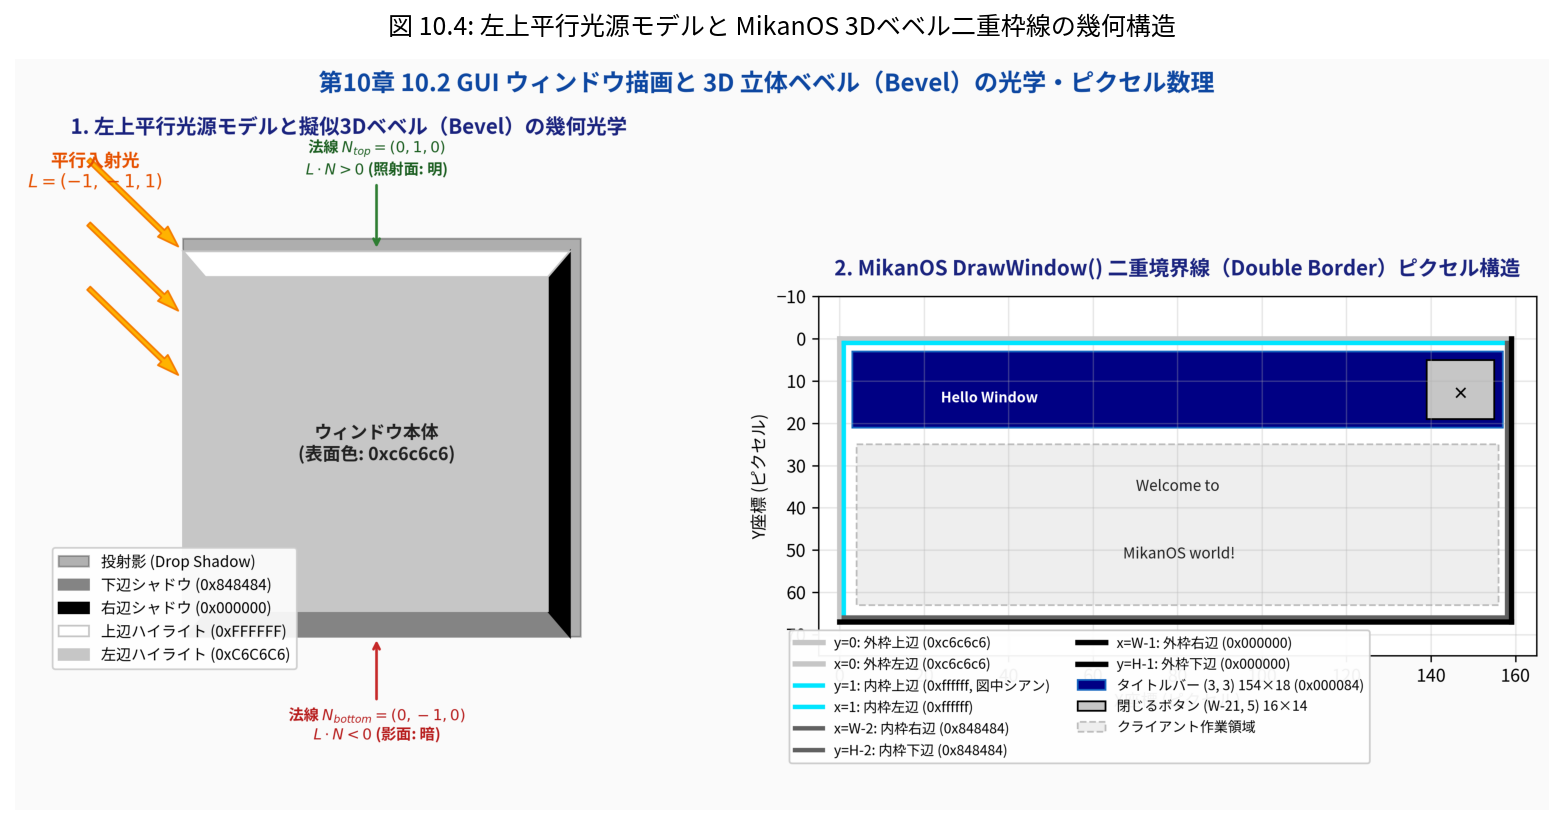

In [2]:
# 図版 10.4: 3Dベベル立体枠の光学モデルとピクセル数理の生成と表示
from PIL import Image
import matplotlib.pyplot as plt
from common import plot_fig10_04_window_bevel_and_light_source_math

fig_path = plot_fig10_04_window_bevel_and_light_source_math("10/result/fig10_04_window_bevel_and_light_source_math.png")
img = Image.open(fig_path)

plt.figure(figsize=(15, 6.5), dpi=150)
plt.imshow(img)
plt.axis("off")
plt.title("図 10.4: 左上平行光源モデルと MikanOS 3Dベベル二重枠線の幾何構造", fontsize=12, pad=12)
plt.show()

---  
## 2. 光源モデル（Light Source Model）と3Dベベル（立体枠）の数理導出

### 2.1 人間の視覚が2D画面上で「立体」を認識する原理

平坦な液晶ディスプレイ上で、ピクセルの明暗対比（コントラスト）のみを用いて「隆起した板（立体ウィンドウ）」や「押し込めるボタン」を錯覚させる技術が**擬似3Dベベル（Pseudo-3D Bevel）**です。

この錯覚の基礎となっているのが、コンピュータグラフィックスにおける**「左上平行光源の仮定」**です：
- **光源の位置**: 画面の無限遠左上、斜め手前方向から平行光線が照射されていると仮定します。
  $$\vec{L} = \frac{1}{\sqrt{3}} \begin{pmatrix} -1 \\ -1 \\ 1 \end{pmatrix}$$
- **ランバートの余弦則（Lambert's Cosine Law）**:
  面の法線ベクトルを $\vec{N}$ としたとき、反射光強度 $I$ は入射角の余弦に比例します：
  $$I = I_0 \cdot \max(0, \vec{L} \cdot \vec{N})$$

隆起した直方体の4つの斜面（上・左・右・下）における法線と反射強度の関係を整理すると下表のようになります：

| 面 | 画面上の向き | 面法線ベクトル $\vec{N}$ | 内積 $\vec{L} \cdot \vec{N}$ | 視覚的光学的分類 | MikanOS 採用カラー | 16進カラーコード |
|:---:|:---:|:---:|:---:|:---:|:---:|:---:|
| **内枠上辺 / 内枠左辺** | 上・左向き（直接受光） | $(-0.707, -0.707, 0.5)$ | 正（大：直接反射） | **ハイライト (Direct Highlight)** | **白 (White)** | `0xffffff` |
| **外枠上辺 / 外枠左辺** | 上・左向き（間接受光） | $(-1, 0, 0) / (0, -1, 0)$ | 正（中：拡散反射） | **ソフトハイライト (Indirect)** | **明灰 (Light Gray)** | `0xc6c6c6` |
| **ウィンドウ地色** | 正面向き | $(0, 0, 1)$ | 正（基準面） | **ベース表面 (Face / Surface)** | **標準灰 (Standard Gray)** | `0xc6c6c6` |
| **内枠右辺 / 内枠下辺** | 右・下向き（浅い影） | $(0.707, 0.707, 0.5)$ | 負（微弱散乱光のみ） | **ソフトシャドウ (Subtle Drop)** | **暗灰 (Dark Gray)** | `0x848484` |
| **外枠右辺 / 外枠下辺** | 右・下向き（完全遮光） | $(1, 0, 0) / (0, 1, 0)$ | 負（完全な陰影） | **ディープシャドウ (Deep Shadow)** | **黒 (Black)** | `0x000000` |

### 2.2 二重枠線（Double Border）の10本矩形塗りつぶし数理

`kernel/window.cpp` の `DrawWindow()` では、以下の10回の `FillRectangle` 呼び出しにより、1ピクセルの狂いもなく完璧な立体枠を構築します：

```cpp
const auto win_w = writer.Width();
const auto win_h = writer.Height();

fill_rect({0, 0},         {win_w, 1},             0xc6c6c6); // ① 外枠上辺 (y=0)
fill_rect({1, 1},         {win_w - 2, 1},         0xffffff); // ② 内枠上辺 (y=1)
fill_rect({0, 0},         {1, win_h},             0xc6c6c6); // ③ 外枠左辺 (x=0)
fill_rect({1, 1},         {1, win_h - 2},         0xffffff); // ④ 内枠左辺 (x=1)
fill_rect({win_w - 2, 1}, {1, win_h - 2},         0x848484); // ⑤ 内枠右辺 (x=W-2)
fill_rect({win_w - 1, 0}, {1, win_h},             0x000000); // ⑥ 外枠右辺 (x=W-1)
fill_rect({2, 2},         {win_w - 4, win_h - 4}, 0xc6c6c6); // ⑦ 本体背景 ((2,2)〜(W-3, H-3))
fill_rect({3, 3},         {win_w - 6, 18},        0x000084); // ⑧ タイトルバー ((3,3)〜(W-4, 20))
fill_rect({1, win_h - 2}, {win_w - 2, 1},         0x848484); // ⑨ 内枠下辺 (y=H-2)
fill_rect({0, win_h - 1}, {win_w, 1},             0x000000); // ⑩ 外枠下辺 (y=H-1)
```

> [!IMPORTANT]
> **なぜ1ピクセル単位の順序が重要なのか？**
> - 角（コーナー）のピクセルは上辺と側辺の境界が重なり合います。例えば、左上隅 $(0, 0)$ は上辺と左辺の双方が `0xc6c6c6` であるため整合します。
> - 右上隅 $(W-1, 0)$ は、外枠上辺の右端ですが、⑥の外枠右辺 `(win_w - 1, 0)` の黒 `0x000000` で上書きされるため、右上から右辺・下辺へと影の輪郭線が途切れることなく連続します。
> - 内枠においても、$(1, 1)$ の純白ハイライトと $(W-2, H-2)$ の暗灰シャドウが斜めに対峙することで、劇的な立体感が創出されます。

In [3]:
# 対話型 Python 実験 1: 3Dベベル枠線のピクセル検査と光学セグメント検証
from common import WindowBevelDecoratorSim

sim = WindowBevelDecoratorSim(width=160, height=68, title="Hello Window")
segments = sim.get_border_segments()

print("=== MikanOS Window 3D Bevel 境界線セグメント一覧 ===")
print(f"{'セグメント名':<20} | {'矩形 (x, y, w, h)':<18} | {'カラー (HEX)':<12} | {'光学的役割'}")
print("-" * 75)
for seg in segments:
    r = seg['rect']
    rect_str = f"({r[0]}, {r[1]}, {r[2]}, {r[3]})"
    print(f"{seg['name']:<20} | {rect_str:<18} | {seg['hex']:<12} | {seg['role']}")

print("\n--- 境界ピクセルの実測サンプリング ---")
print("左上隅外枠 (0, 0):", sim.get_pixel(0, 0), "-> 0xc6c6c6 (Light Gray)")
print("左上隅内枠 (1, 1):", sim.get_pixel(1, 1), "-> 0xffffff (White Direct Highlight)")
print("右下隅内枠 (158, 66):", sim.get_pixel(158, 66), "-> 0x848484 (Dark Gray Inner Shadow)")
print("右下隅外枠 (159, 67):", sim.get_pixel(159, 67), "-> 0x000000 (Black Deep Shadow)")
print("タイトルバー内部 (10, 10):", sim.get_pixel(10, 10), "-> 0x000084 (Navy Blue)")
print("本体背景 (50, 40):", sim.get_pixel(50, 40), "-> 0xc6c6c6 (Client Gray Base)")

=== MikanOS Window 3D Bevel 境界線セグメント一覧 ===
セグメント名               | 矩形 (x, y, w, h)    | カラー (HEX)    | 光学的役割
---------------------------------------------------------------------------
Outer Top Edge       | (0, 0, 160, 1)     | 0xc6c6c6     | Outer Highlight (Indirect)
Inner Top Edge       | (1, 1, 158, 1)     | 0xffffff     | Inner Highlight (Direct Light)
Outer Left Edge      | (0, 0, 1, 68)      | 0xc6c6c6     | Outer Highlight (Indirect)
Inner Left Edge      | (1, 1, 1, 66)      | 0xffffff     | Inner Highlight (Direct Light)
Inner Right Edge     | (158, 1, 1, 66)    | 0x848484     | Inner Shadow (Subtle Drop)
Outer Right Edge     | (159, 0, 1, 68)    | 0x000000     | Outer Shadow (Deep Shadow)
Window Background    | (2, 2, 156, 64)    | 0xc6c6c6     | Client/Dialog Base Surface
Title Bar            | (3, 3, 154, 18)    | 0x000084     | Window Drag / Focus Handle
Inner Bottom Edge    | (1, 66, 158, 1)    | 0x848484     | Inner Shadow (Subtle Drop)
Outer Bottom Edge    | (0, 67, 160

---  
## 3. 閉じるボタン（Close Button）の 16×14 ドット絵パレット展開アルゴリズム

### 3.1 ベアメタルOSにおけるドット絵埋め込み（ASCIIアートリソース）の意義

一般的なデスクトップOSでは、PNGやSVGなどの画像リソースをファイルシステムからロードしてGUIパーツを描画します。しかし、**OS起動直後のベアメタル環境では、ファイルシステム（FAT等）も画像デコーダ（libpng等）もまだ存在しません**。

そのため、MikanOSではマウスカーソル（第6章）と同様に、閉じるボタンのドット絵を**C++ソースコード内の2次元文字配列（ASCIIアートパターン）**として静的に埋め込んでいます：

```cpp
namespace {
  const int kCloseButtonWidth = 16;
  const int kCloseButtonHeight = 14;
  const char close_button[kCloseButtonHeight][kCloseButtonWidth + 1] = {
    "...............@",
    ".:::::::::::::$@",
    ".:::::::::::::$@",
    ".:::@@::::@@::$@",
    ".::::@@::@@:::$@",
    ".:::::@@@@::::$@",
    ".::::::@@:::::$@",
    ".:::::@@@@::::$@",
    ".::::@@::@@:::$@",
    ".:::@@::::@@::$@",
    ".:::::::::::::$@",
    ".:::::::::::::$@",
    ".$$$$$$$$$$$$$$@",
    "@@@@@@@@@@@@@@@@",
  };
}
```

### 3.2 4値カラーパレットと幾何学的立体構造

このわずか $16 \times 14 = 224$ ピクセルのパターンには、計算し尽くされた立体デザインが凝縮されています：

1. **`'.'` (白 `0xffffff`)**:
   - 最上行（row 0）および最左列（col 0）。ボタンの上辺と左辺に配置され、**「光が当たってボタンが浮き上がっている」**立体感を演出します。
2. **`':'` (灰 `0xc6c6c6`)**:
   - ボタンの表面地色。ウィンドウ背景と同じグレーで統一されています。
3. **`'$'` (暗灰 `0x848484`)**:
   - 下から2行目（row 12）および右から2列目（col 14）。ボタンの右側と下側に生じる**「内側のソフトな陰影」**を表現します。
4. **`'@'` (黒 `0x000000`)**:
   - 最下行（row 13）、最右列（col 15）、および**中央の「×」印（Cross Glyph）**。
   - 「×」印は row 3〜9 にかけて2ピクセル幅の斜めストロークが左右対称（Symmetric）に交差するように設計されています。

### 3.3 右上配置の座標計算数理

ウィンドウ右上端からのマージンを $5$ ピクセルとすると、閉じるボタンの左上原点 $(x_{btn}, y_{btn})$ は以下のように計算されます：
$$x_{btn} = W_{win} - 5 - W_{btn} = 160 - 5 - 16 = 139$$
$$y_{btn} = 5 \quad (\text{タイトルバー上端 } y=3 \text{ から 2px 内側})$$

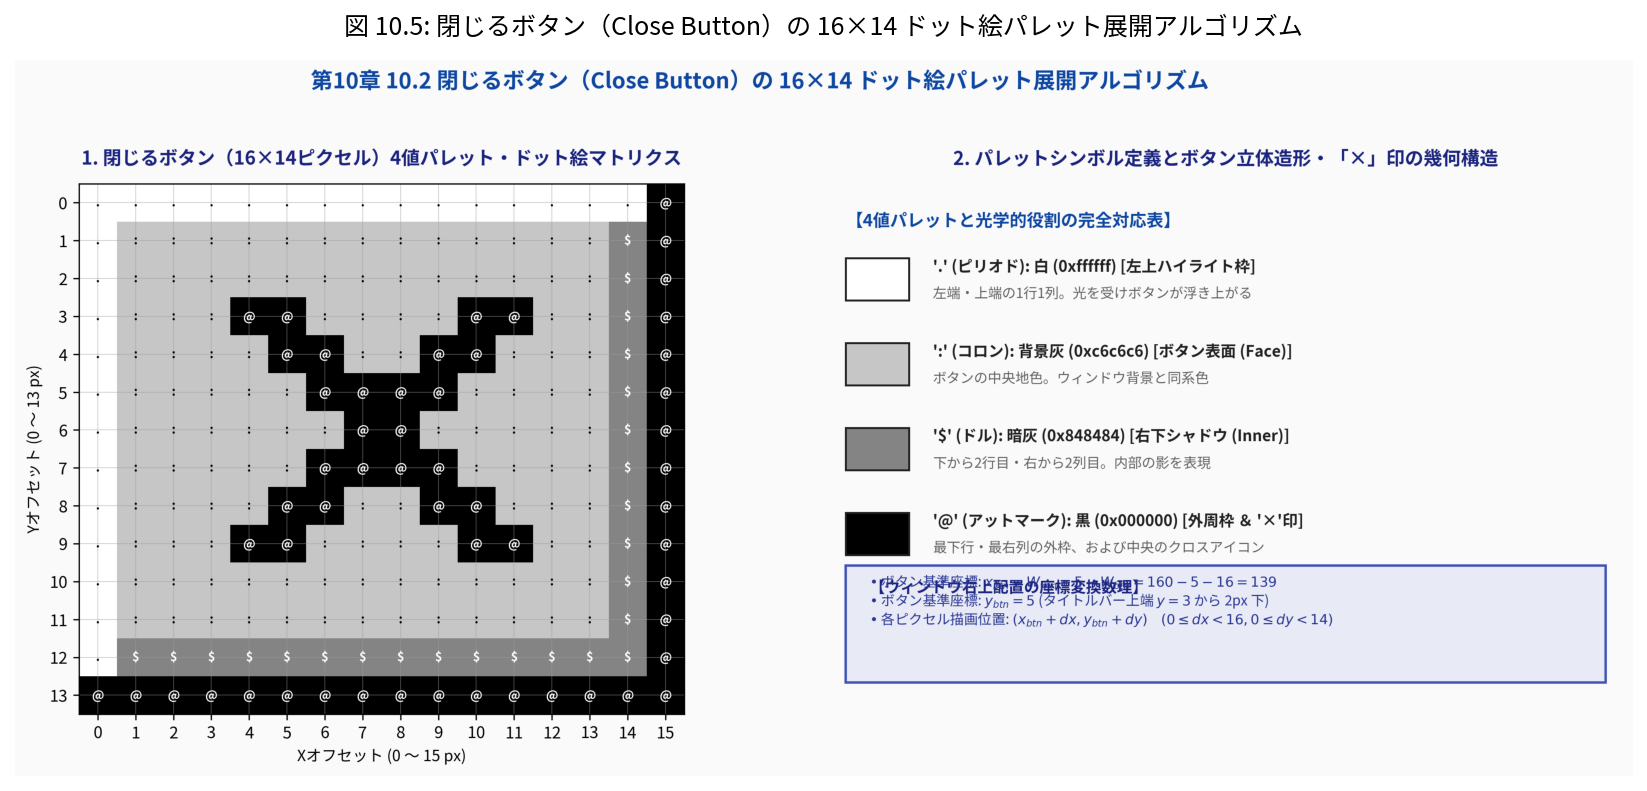

In [4]:
# 図版 10.5: 閉じるボタン（16×14）4値パレット・ドット絵マトリクスの生成と表示
from PIL import Image
import matplotlib.pyplot as plt
from common import plot_fig10_05_close_button_bitmap_matrix

fig_path = plot_fig10_05_close_button_bitmap_matrix("10/result/fig10_05_close_button_bitmap_matrix.png")
img = Image.open(fig_path)

plt.figure(figsize=(15, 6.2), dpi=150)
plt.imshow(img)
plt.axis("off")
plt.title("図 10.5: 閉じるボタン（Close Button）の 16×14 ドット絵パレット展開アルゴリズム", fontsize=12, pad=12)
plt.show()

In [5]:
# 対話型 Python 実験 2: 閉じるボタンのドット絵パレット解析とクロスシンボルの検証
from common import CLOSE_BUTTON_PATTERN, COLOR_WHITE, COLOR_LIGHT_GRAY, COLOR_DARK_GRAY, COLOR_BLACK

print("=== 閉じるボタン 16×14 文字パターンのシンボル出現頻度解析 ===")
symbol_counts = {".": 0, ":": 0, "$": 0, "@": 0}
for row in CLOSE_BUTTON_PATTERN:
    for ch in row:
        symbol_counts[ch] += 1

total_px = 16 * 14
print(f"• '.' (白 0xffffff / ハイライト): {symbol_counts['.']:2d} px ({symbol_counts['.']/total_px*100:4.1f}%)")
print(f"• ':' (灰 0xc6c6c6 / 表面地色)  : {symbol_counts[':']:2d} px ({symbol_counts[':']/total_px*100:4.1f}%)")
print(f"• '$' (暗灰 0x848484 / シャドウ): {symbol_counts['$']:2d} px ({symbol_counts['$']/total_px*100:4.1f}%)")
print(f"• '@' (黒 0x000000 / 枠＆'×')  : {symbol_counts['@']:2d} px ({symbol_counts['@']/total_px*100:4.1f}%)")
print(f"合計ピクセル数: {total_px} px")

# クロス中心ピクセルの検証
print("\n--- '×' 印の中心座標（row 6）のピクセル構成 ---")
row6 = CLOSE_BUTTON_PATTERN[6]
print("Row 6 Pattern:", " ".join(row6))
print("Col 7 & 8 (Center Cross):", repr(row6[7]), repr(row6[8]), "-> '@' (Black Pixel)")

=== 閉じるボタン 16×14 文字パターンのシンボル出現頻度解析 ===
• '.' (白 0xffffff / ハイライト): 27 px (12.1%)
• ':' (灰 0xc6c6c6 / 表面地色)  : 117 px (52.2%)
• '$' (暗灰 0x848484 / シャドウ): 25 px (11.2%)
• '@' (黒 0x000000 / 枠＆'×')  : 55 px (24.6%)
合計ピクセル数: 224 px

--- '×' 印の中心座標（row 6）のピクセル構成 ---
Row 6 Pattern: . : : : : : : @ @ : : : : : $ @
Col 7 & 8 (Center Cross): '@' '@' -> '@' (Black Pixel)


---  
## 4. MikanOS 公式リポジトリ差分完全解剖 (`osbook_day10a` ➔ `osbook_day10b`)

### 4.1 `kernel/window.hpp`, `kernel/window.cpp` の差分

ウィンドウ装飾を行う関数 `DrawWindow()` が新たに追加されました：

```cpp
// kernel/window.hpp
void DrawWindow(PixelWriter& writer, const char* title);
```

`ToColor()` 関数により、32ビットRGB値 `0xRRGGBB` を `PixelColor` 構造体へ変換しています：
```cpp
namespace {
  constexpr PixelColor ToColor(uint32_t c) {
    return {
      static_cast<uint8_t>((c >> 16) & 0xff),
      static_cast<uint8_t>((c >> 8) & 0xff),
      static_cast<uint8_t>(c & 0xff)
    };
  }
}
```

### 4.2 `kernel/main.cpp` の差分: 初めてのウィンドウ生成とレイヤ登録

`KernelMainNewStack()` において、メインウィンドウを生成してデスクトップに配置するコードが追加されました：

```cpp
  // 1. 幅160×高さ68のウィンドウインスタンス生成
  auto main_window = std::make_shared<Window>(
      160, 68, frame_buffer_config.pixel_format);
  
  // 2. 3D立体枠・タイトルバー・閉じるボタンの描画
  DrawWindow(*main_window->Writer(), "Hello Window");
  
  // 3. クライアント領域へのテキスト描画
  WriteString(*main_window->Writer(), {24, 28}, "Welcome to", {0, 0, 0});
  WriteString(*main_window->Writer(), {24, 44}, " MikanOS world!", {0, 0, 0});

  // 4. レイヤマネージャへの登録と座標 (300, 100) への移動
  auto main_window_layer_id = layer_manager->NewLayer()
    .SetWindow(main_window)
    .Move({300, 100})
    .ID();

  // 5. Z オーダーの設定と初期描画
  layer_manager->UpDown(bglayer_id, 0);          // 背景レイヤ: Z=0
  layer_manager->UpDown(mouse_layer_id, 1);      // マウスレイヤ: Z=1 (過渡的)
  layer_manager->UpDown(main_window_layer_id, 1); // ウィンドウレイヤ: Z=1 (マウスがZ=2へ繰り上がり)
  layer_manager->Draw();
```

> [!TIP]
> **UpDown による Z オーダーの繰り上がり機構**
> `layer_manager->UpDown(id, 1)` を呼ぶと、その ID のレイヤが Z=1 に挿入され、元々 Z=1 にいたマウスレイヤは自動的に Z=2 へ繰り上がります。
> その結果、**「背景 (Z=0) < ウィンドウ (Z=1) < マウスカーソル (Z=2)」** という正しい前後関係が保たれ、マウスカーソルがウィンドウの上をスムーズに移動できるようになります。

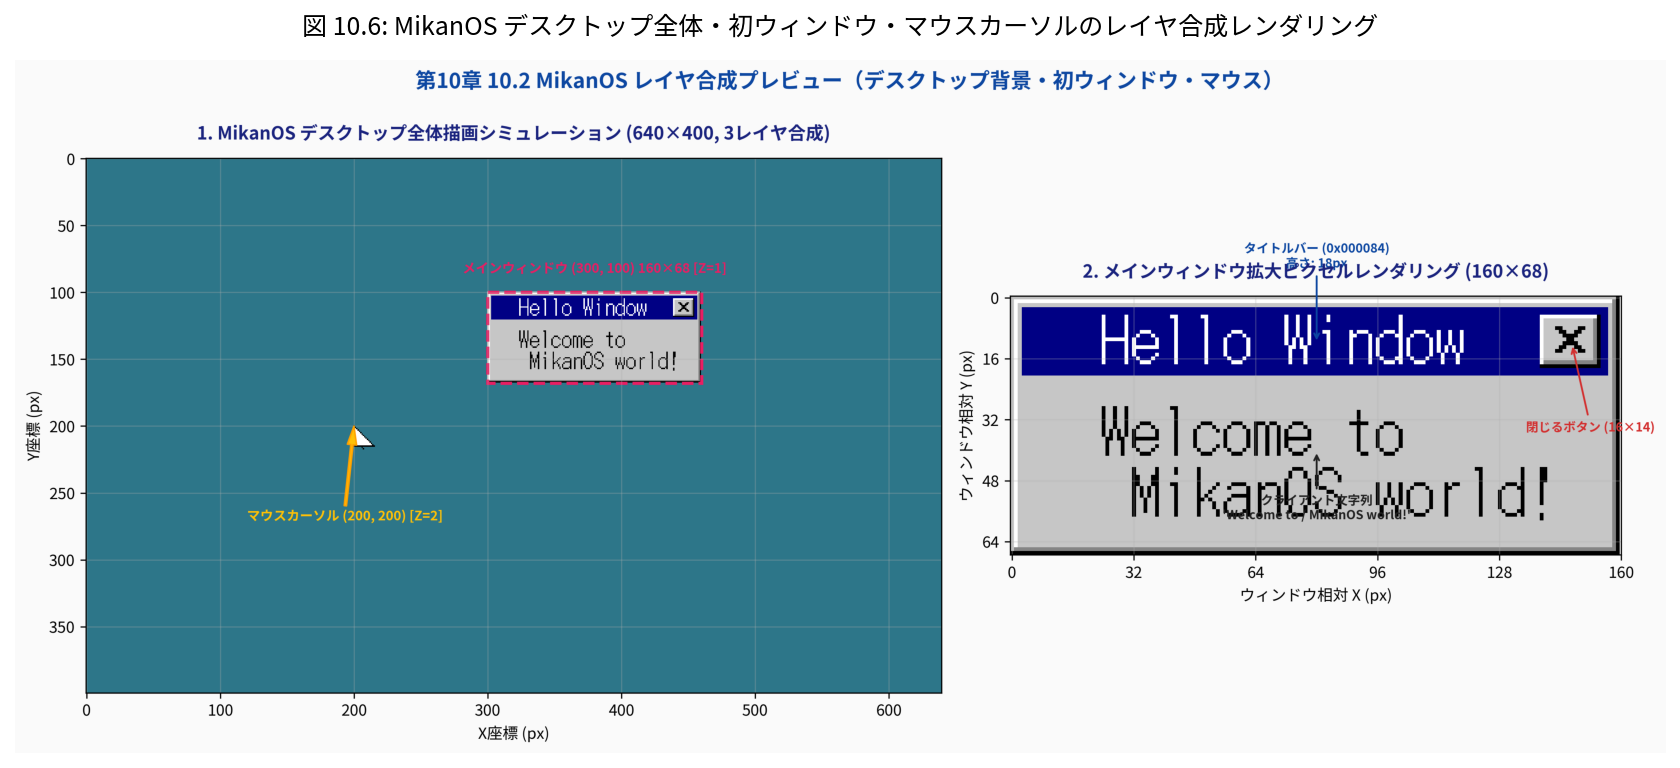

In [6]:
# 図版 10.6: MikanOS デスクトップ全体描画と初ウィンドウの拡大レンダリングの生成と表示
from PIL import Image
import matplotlib.pyplot as plt
from common import plot_fig10_06_first_window_composition_render

fig_path = plot_fig10_06_first_window_composition_render("10/result/fig10_06_first_window_composition_render.png")
img = Image.open(fig_path)

plt.figure(figsize=(15, 6.0), dpi=150)
plt.imshow(img)
plt.axis("off")
plt.title("図 10.6: MikanOS デスクトップ全体・初ウィンドウ・マウスカーソルのレイヤ合成レンダリング", fontsize=12, pad=12)
plt.show()

In [7]:
# 対話型 Python 実験 3: レイヤ合成の整合性とウィンドウ幾何境界の検証
from common import WindowBevelDecoratorSim
import numpy as np

sim = WindowBevelDecoratorSim(width=160, height=68, title="Hello Window")
client = sim.get_client_area()

print("=== ウィンドウ内部ジオメトリの計算結果 ===")
print(f"• ウィンドウ全体寸法: 幅 {sim.width} px × 高さ {sim.height} px")
print(f"• タイトルバー寸法  : 幅 {sim.width - 6} px × 高さ 18 px (原点: (3, 3))")
print(f"• 閉じるボタン寸法  : 幅 16 px × 高さ 14 px (原点: ({sim.width - 21}, 5))")
print(f"• クライアント作業域: 幅 {client['width']} px × 高さ {client['height']} px (原点: ({client['x']}, {client['y']}))")

desktop = sim.composite_onto_desktop(640, 400, win_pos=(300, 100), mouse_pos=(200, 200))
print("\n--- デスクトップ合成結果のサンプリング ---")
print("デスクトップ背景ピクセル (50, 50) RGB:", desktop[50, 50], "-> [45, 118, 137] (Teal Desk)")
print("ウィンドウタイトルバー (300+10, 100+10) RGB:", desktop[110, 310], "-> [0, 0, 132] (Title Bar Navy)")
print("ウィンドウ白ハイライト (300+1, 100+1) RGB:", desktop[101, 301], "-> [255, 255, 255] (Direct Light)")

=== ウィンドウ内部ジオメトリの計算結果 ===
• ウィンドウ全体寸法: 幅 160 px × 高さ 68 px
• タイトルバー寸法  : 幅 154 px × 高さ 18 px (原点: (3, 3))
• 閉じるボタン寸法  : 幅 16 px × 高さ 14 px (原点: (139, 5))
• クライアント作業域: 幅 152 px × 高さ 39 px (原点: (4, 25))

--- デスクトップ合成結果のサンプリング ---
デスクトップ背景ピクセル (50, 50) RGB: [ 45 118 137] -> [45, 118, 137] (Teal Desk)
ウィンドウタイトルバー (300+10, 100+10) RGB: [  0   0 132] -> [0, 0, 132] (Title Bar Navy)
ウィンドウ白ハイライト (300+1, 100+1) RGB: [255 255 255] -> [255, 255, 255] (Direct Light)


---  
## 5. C++20 単体検証プログラムのコンパイルと実行

本リポジトリでは、MikanOS の `DrawWindow` および `Window` クラスの動作をホスト環境（Linux / macOS / WSL / Colab）の標準 C++20 で完全に再現・単体テストできるプログラム `src/ch10/os_chapter10_first_window.cpp` を実装しています。

このプログラムでは以下の項目を厳密にアサーション検証します：
1. **3Dベベル外枠・内枠のハイライトおよびシャドウピクセル色の一致**
2. **タイトルバー（154×18 px）の `0x000084` 塗りつぶしとタイトル文字列の配置**
3. **閉じるボタン（16×14 px）の4色パレット展開と中央「×」印のビットマップ一致**
4. **デスクトップ画面（640×400）へのウィンドウレイヤ合成と背景汚染ゼロの検証**

In [8]:
!cmake -B build -S . > /dev/null
!cmake --build build --target ch10_first_window
!./build/bin/ch10_first_window

CMake Error: The source directory "/home/student/Documents/GitHub/study-mikanos/10" does not appear to contain CMakeLists.txt.
Specify --help for usage, or press the help button on the CMake GUI.


Error: /home/student/Documents/GitHub/study-mikanos/10/build is not a directory


/bin/bash: line 1: ./build/bin/ch10_first_window: No such file or directory


---  
## 6. セルフチェック演習問題（理解度確認クイズ）

本節で学んだウィンドウデコレーション、3Dベベル光学数理、閉じるボタンの設計に関する理解度を以下のクイズで確認してください。

### 【設問】
1. **問1**: 2Dディスプレイ上で「手前に隆起した立体ウィンドウ」を錯覚させるため、古典的GUIで広く採用されている平行光源の照射方向はどれか？
   - (A) 画面の真下から真上方向
   - (B) 画面の無限遠左上から右下・手前方向
   - (C) 画面の中央から外側に向かう放射方向
   - (D) 画面の右上から左下方向

2. **問2**: MikanOS の `DrawWindow()` において、左上からの光源を直接受けて最も強い反射光を放つ「内枠上辺」および「内枠左辺」に指定されているカラーコードはどれか？
   - (A) `0xc6c6c6` (明灰)
   - (B) `0x848484` (暗灰)
   - (C) `0xffffff` (白)
   - (D) `0x000000` (黒)

3. **問3**: 閉じるボタン（Close Button）の 16×14 ドット絵パターンにおいて、中央の「×」印およびボタンの最外周枠を描画するために割り当てられている文字シンボルはどれか？
   - (A) `.` (ピリオド)
   - (B) `:` (コロン)
   - (C) `$` (ドルマーク)
   - (D) `@` (アットマーク)

4. **問4**: ウィンドウの幅が $W=160$ ピクセルで、閉じるボタンの幅が $16$ ピクセル、右端マージンが $5$ ピクセルのとき、閉じるボタンのX座標基準位置 $x_{btn}$ はいくらか？
   - (A) $139$
   - (B) $144$
   - (C) $149$
   - (D) $155$

5. **問5**: `KernelMainNewStack()` で `layer_manager->UpDown(bglayer_id, 0);`、`layer_manager->UpDown(mouse_layer_id, 1);`、`layer_manager->UpDown(main_window_layer_id, 1);` の順に呼び出したとき、最終的なレイヤの高さ（Zオーダー）の関係として正しいものはどれか？
   - (A) 背景 (Z=0) < マウス (Z=1) < ウィンドウ (Z=2)
   - (B) 背景 (Z=0) < ウィンドウ (Z=1) < マウス (Z=2)
   - (C) ウィンドウ (Z=0) < 背景 (Z=1) < マウス (Z=2)
   - (D) マウス (Z=0) < ウィンドウ (Z=1) < 背景 (Z=2)

In [9]:
# クイズの解答を入力して自己採点を行ってください（例: ['B', 'C', 'D', 'A', 'B']）
my_answers = ['B', 'C', 'D', 'A', 'B']

correct_keys = ['B', 'C', 'D', 'A', 'B']
explanations = [
    "問1 正解 [B]: 古典的GUIでは左上からの平行光線 L = (-1, -1, 1) を基準とし、上辺・左辺を明、下辺・右辺を暗とすることで凹凸感を演出します。",
    "問2 正解 [C]: 内枠の上辺と左辺には最も明るい純白 (0xffffff) が割り当てられ、光が直接当たるエッジ（Direct Highlight）を表現します。",
    "問3 正解 [D]: シンボル '@' は黒 (0x000000) に対応し、外枠および中央の '×' グリフを描画します。",
    "問4 正解 [A]: x_btn = W - 5 - 16 = 160 - 21 = 139 です。",
    "問5 正解 [B]: 後から同じ Z=1 に挿入された main_window が Z=1 となり、既存のマウスレイヤは押し出されて Z=2 となるため、マウスが最前面に維持されます。",
]

score = sum(1 for a, c in zip(my_answers, correct_keys) if a.upper() == c)
print(f"=== セルフチェック採点結果: {score} / {len(correct_keys)} 点 ===\n")
for i, (ans, cor, exp) in enumerate(zip(my_answers, correct_keys, explanations), 1):
    status = "✅ 正解" if ans.upper() == cor else f"❌ 不正解 (あなたの回答: {ans})"
    print(f"問{i}: {status}\n   解説: {exp}\n")
if score == len(correct_keys):
    print("🎉 素晴らしい！第10章 10.2節の理論と実装を完全にマスターしました！")

=== セルフチェック採点結果: 5 / 5 点 ===

問1: ✅ 正解
   解説: 問1 正解 [B]: 古典的GUIでは左上からの平行光線 L = (-1, -1, 1) を基準とし、上辺・左辺を明、下辺・右辺を暗とすることで凹凸感を演出します。

問2: ✅ 正解
   解説: 問2 正解 [C]: 内枠の上辺と左辺には最も明るい純白 (0xffffff) が割り当てられ、光が直接当たるエッジ（Direct Highlight）を表現します。

問3: ✅ 正解
   解説: 問3 正解 [D]: シンボル '@' は黒 (0x000000) に対応し、外枠および中央の '×' グリフを描画します。

問4: ✅ 正解
   解説: 問4 正解 [A]: x_btn = W - 5 - 16 = 160 - 21 = 139 です。

問5: ✅ 正解
   解説: 問5 正解 [B]: 後から同じ Z=1 に挿入された main_window が Z=1 となり、既存のマウスレイヤは押し出されて Z=2 となるため、マウスが最前面に維持されます。

🎉 素晴らしい！第10章 10.2節の理論と実装を完全にマスターしました！


---  
## 7. 本節のまとめと次節（10.3 高速カウンタ）への展望

### 本節で達成した成果
1. **GUI ウィンドウ装飾の数理的解明**:
   - クライアント領域と非クライアント装飾領域の二層構造を確立しました。
   - 左上平行光源モデルに基づき、二重ボーダー（外枠・内枠）の10本矩形塗りつぶし数理を導出しました。
2. **閉じるボタン（16×14）のパレット展開**:
   - 4値文字シンボル（`.`, `:`, `$`, `@`）による省サイズな静的ビットマップ埋め込みと、右上配置の幾何数理を確立しました。
3. **レイヤシステムによる合成**:
   - `LayerManager` にウィンドウレイヤを登録し、Z オーダーの繰り上がりによって「背景 < ウィンドウ < マウス」の階層構造を実現しました。

### 次節への課題: 「高速カウンタと画面のチラつき（Flickering / Tearing）」

ついに画面上に美しいウィンドウを表示することに成功しました！
しかし、次節（10.3節 `osbook_day10c`）では、このウィンドウ内に**「毎フレーム高速にインクリメントされる数字カウンタ」**を描画する実験を行います。

そこで我々は、GUI開発者が必ず一度は直面する悪夢――**「画面が激しくチラチラと明滅する現象（チラつき / Flickering）」**という巨大な技術的障壁に直面することになります。
なぜ画面はチラつくのか？どうすればこのチラつきを根絶できるのか？
次節 10.3「高速カウンタ」へと学習を進めましょう！